PermutationExplainer explainer: 1001it [06:10,  2.70it/s]                          
C:\Users\ADMIN\AppData\Local\Temp\ipykernel_15596\1266140846.py:32: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_sample, show=False)


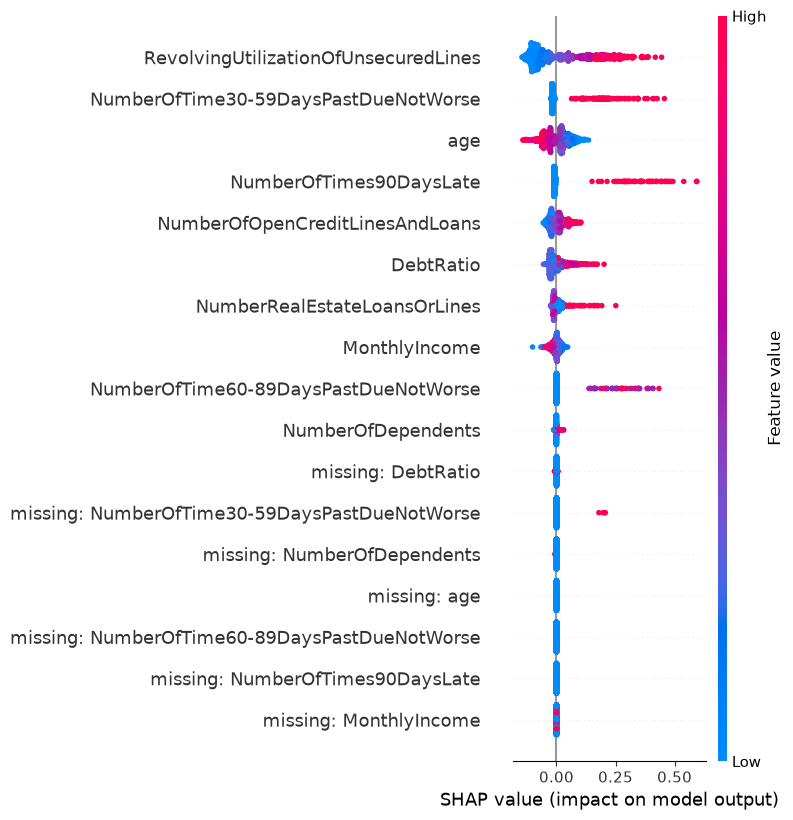

In [1]:
import sys
sys.path.append("..")

import joblib
import shap
import pandas as pd
import matplotlib.pyplot as plt

from src.preprocessing import load_data, clean_data, split_data

data = clean_data(load_data())
X_train, X_test, y_train, y_test = split_data(data)

model = joblib.load("../models/loan_default_model.joblib")
prep = model.named_steps["prep"]
clf = model.named_steps["model"]

# Transform the test data and give columns readable names
X_test_t = prep.transform(X_test)
names = [n.replace("num__", "").replace("missingindicator_", "missing: ")
         for n in prep.get_feature_names_out()]
X_sample = pd.DataFrame(X_test_t, columns=names).sample(1000, random_state=42)

# Explain the default PROBABILITY, passing plain arrays to avoid feature-name warnings
def predict_default_proba(X):
    return clf.predict_proba(X)[:, 1]

background = shap.sample(X_sample, 100, random_state=42)
explainer = shap.Explainer(predict_default_proba, background.values, feature_names=names)
sv = explainer(X_sample.values)

shap.summary_plot(sv, X_sample, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()